# what a short SPY put is paid for

Selling out-of-the-money puts on the S&P 500 is one of the oldest ways to earn a risk premium. This notebook asks
two precise questions about it, with 2012–2025 SPY option data.

1. What is a put worth under real-world probabilities, and how much more than that does the market pay for it?
2. If you sell the put and delta-hedge it, where does the P&L come from, day by day?

The answers, in short. Puts sell at 1.2 times their real-world value at the money and 2.3 times at 5-delta. For the
15-delta put the compensation is about 6.4 basis points of SPY a week, 38% of the price, but the estimate is not
precise enough to trade on, and one bad week costs about a year of it. Delta-hedged, the trade is variance carry. It
earns about 18 bp a week from time decay and pays about 15 bp for realised moves and 1 bp in costs.

The notebook explains every method from scratch and demonstrates each one on synthetic data that runs live. The
real-data results come from running the same methods on licensed end-of-day SPY option chains, which can't be shared,
so they enter as aggregate tables (bucket and component averages) from which the figures are drawn.

To follow along you need to know what a call and a put are, what delta and gamma mean, and a little probability. Run
the cells top to bottom, which takes about a minute. The notebook requires `numpy`, `scipy`, `pandas` and `matplotlib`.

## 0. Setup

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import integrate, stats
from scipy.stats import norm

BLUE, ORANGE, AQUA, YELLOW, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.figsize": (7, 4), "figure.dpi": 110, "axes.grid": True, "grid.color": GRID, "axes.edgecolor": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "xtick.color": MUTED, "ytick.color": MUTED,
    "lines.linewidth": 2, "lines.markersize": 6, "legend.frameon": False, "axes.titleweight": "bold",
})
pd.set_option("display.precision", 3)


def check(condition, message):
    # Every claim in the text is backed by a check like this one. If a check fails, the notebook stops.
    assert condition, "FAILED: " + message
    print("ok  " + message)


def black76(F, K, T, r, sigma, kind):
    # European option on a forward F, discounted at r
    F, K, T, r, sigma = (np.asarray(x, dtype=float) for x in (F, K, T, r, sigma))
    s = sigma*np.sqrt(T)
    d1 = (np.log(F/K) + s*s/2)/s
    d2 = d1 - s
    call = np.exp(-r*T)*(F*norm.cdf(d1) - K*norm.cdf(d2))
    put = np.exp(-r*T)*(K*norm.cdf(-d2) - F*norm.cdf(-d1))
    return np.where(np.char.equal(np.asarray(kind, dtype=str), "call"), call, put)

## 1. Two prices for the same put

A put with strike $K$ and expiry $T$ pays $(K - S_T)^+$. There are two ways to value that payoff today.

The market price is a risk-neutral expectation. It uses the probabilities $\mathbb Q$ under which every traded asset
earns the risk-free rate, and it is what you see in the quotes

$$V^{\mathbb Q} = e^{-rT}\,\mathbb E^{\mathbb Q}\big[(K - S_T)^+\big]$$

The real-world value uses the physical probabilities $\mathbb P$, the ones that describe how SPY actually moves

$$V^{\mathbb P} = e^{-rT}\,\mathbb E^{\mathbb P}\big[(K - S_T)^+\big]$$

The difference between them is the compensation for carrying the short put. If you sell at the bid, it is

$$C = \text{bid} - V^{\mathbb P}$$

$C$ is not a mispricing. It is the price of insurance against a crash, which investors pay because losses in a crash
hurt more than the same losses in calm times. A large literature (e.g. Bondarenko 2014, Fournier, Jacobs and Orlowski
2024) finds it positive and largest for out-of-the-money puts.

A useful summary is the ratio $V^{\mathbb Q}/V^{\mathbb P}$, the market price per unit of real-world expected payoff. The
cell below shows why this ratio rises as the put moves out of the money, even in the simplest possible world. Prices
come from Black–Scholes with an implied vol of 18%, while the real world is also Black–Scholes but with 15% vol and an
expected return of the risk-free rate plus 5% a year. The 3-vol-point gap is roughly the size of the gap between
implied and realised vol on SPY.

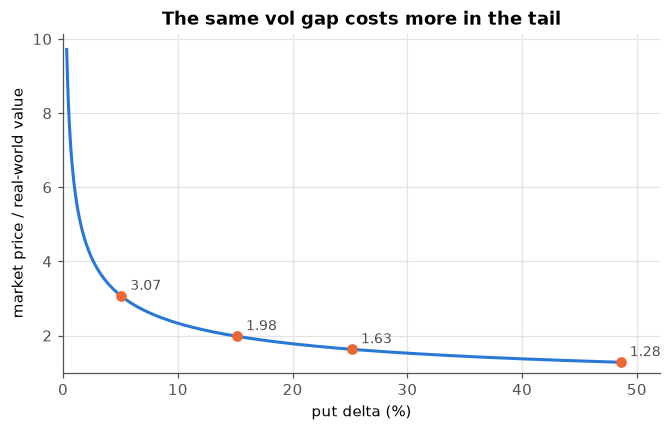

ok  the price-to-value ratio rises steeply as the put moves out of the money


In [2]:
S, r, T = 100.0, 0.03, 7/365
sigma_q, sigma_p, mu = 0.18, 0.15, 0.03 + 0.05
K = np.linspace(93.5, 100, 200)
V_q = black76(S*np.exp(r*T), K, T, r, sigma_q, "put")
V_p = np.exp(-r*T)*black76(S*np.exp(mu*T), K, T, 0.0, sigma_p, "put")   # E^P[(K - S_T)+], discounted at r
d1 = (np.log(S*np.exp(r*T)/K) + sigma_q**2*T/2)/(sigma_q*np.sqrt(T))
put_delta = norm.cdf(-d1)                                                    # |delta| under Q

fig, ax = plt.subplots()
ax.plot(100*put_delta, V_q/V_p, color=BLUE)
for target in (5, 15, 25, 50):
    i = np.argmin(np.abs(100*put_delta - target))
    ax.plot(100*put_delta[i], V_q[i]/V_p[i], "o", color=ORANGE)
    ax.annotate(f"{V_q[i]/V_p[i]:.2f}", (100*put_delta[i], V_q[i]/V_p[i]), textcoords="offset points", xytext=(6, 4),
                color=MUTED, fontsize=9)
ax.set(xlabel="put delta (%)", ylabel="market price / real-world value", xlim=(0, 52), ylim=(1, None),
       title="The same vol gap costs more in the tail")
plt.show()
i5, i50 = np.argmin(np.abs(100*put_delta - 5)), np.argmin(np.abs(100*put_delta - 50))
check(V_q[i5]/V_p[i5] > V_q[i50]/V_p[i50] + 0.5, "the price-to-value ratio rises steeply as the put moves out of the money")

The curve shows the market price of a 7-day put divided by its real-world value, against the put's delta, when
options are priced at 18% vol but the real world has 15% vol and a 5% equity premium. At the money the market charges
about 1.3 times the expected payoff, at 15-delta 2.0 times and at 5-delta 3.1 times. A deep out-of-the-money put only
pays in the tail, and the tail probability reacts much more to the vol gap than the centre does, so the ratio
explodes there.

## 2. Estimating the real-world distribution

The market price is in the quotes, but $V^{\mathbb P}$ needs a model of how SPY moves over the next 5 trading sessions.
The method used here is filtered historical simulation (FHS, Barone-Adesi et al. 1999). It combines a variance
forecast with the empirical shape of past returns.

Let $F_t$ be a forecast, made at the close of day $t$, of the mean daily variance of SPY over the next 5 sessions (in
this study it comes from a HAR model, to be published separately). The 5-day log return $R_t$ (dividends added back)
is standardised by the forecast

$$z_t = \frac{R_t}{\sqrt{5F_t}}$$

If the forecast is good, every $z_t$ has the same distribution, whatever the volatility regime. That is the point of
the "filter". A calm week and a stormy week become comparable, so the shape of the distribution can be learned from all
past weeks at once, and its scale comes from today's forecast.

At an origin $t$ the pool contains every past $z_i$ whose 5-day window has already ended, so no future information is
used. The pool is demeaned, and today's return distribution is built as

$$R = m_t + \sqrt{5F_t}\,z_i,\qquad m_t = (r_f + \text{ERP})\,\tau - \tfrac52 F_t$$

where $\tau$ is the time to expiry in years and the drift makes the expected arithmetic return equal to the T-bill
rate plus an equity risk premium of 5% a year. With $D_t$ the dividends paid before expiry, the price at expiry and the
put's value are

$$S_T^{(i)} = S_t\,e^{R^{(i)}} - D_t,\qquad \hat V^{\mathbb P} = e^{-r_f\tau}\,\frac1N\sum_{i=1}^{N}\big(K - S_T^{(i)}\big)^+$$

and the probability of finishing in the money is the share of the $S_T^{(i)}$ below $K$.

### The catch is the tail

A 15-delta put finishes in the money about 8% of the time, and most of its value comes from a few very bad weeks. The
pool holds 500 to 1,900 values of $z$, but they come from overlapping 5-day windows, so only about a fifth of them are
independent. The cell below shows what that does to the estimate. The true weekly standardised return is a Student t
with 4 degrees of freedom (fat-tailed, like equity returns), and FHS estimates the put value from a pool of $n$
independent draws. It repeats this 2,000 times per pool size and compares the estimate with the exact value.

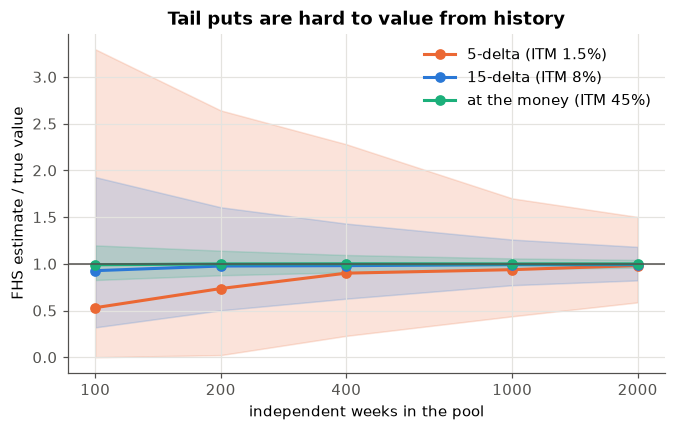

5-delta (ITM 1.5%)       pool of 200: 90% of estimates within 0.02 to 2.64 times the true value
15-delta (ITM 8%)        pool of 200: 90% of estimates within 0.50 to 1.61 times the true value
at the money (ITM 45%)   pool of 200: 90% of estimates within 0.88 to 1.14 times the true value
ok  the 5-delta estimate is far noisier than the at-the-money estimate


In [3]:
nu = 4
scale_t = np.sqrt((nu - 2)/nu)                     # standardised t with mean 0 and variance 1
S, sv = 100.0, 0.01*np.sqrt(5)                     # 1% daily vol over 5 days
m = -sv**2/2


def exact_value(K):
    # E[(K - S e^{m + sv z})+] with z a standardised t
    z_star = (np.log(K/S) - m)/sv
    f = lambda z: (K - S*np.exp(m + sv*z))*stats.t.pdf(z/scale_t, nu)/scale_t
    return integrate.quad(f, -np.inf, z_star, limit=200)[0]


buckets = {"5-delta (ITM 1.5%)": 0.015, "15-delta (ITM 8%)": 0.08, "at the money (ITM 45%)": 0.45}
strikes = {name: S*np.exp(m + sv*scale_t*stats.t.ppf(p, nu)) for name, p in buckets.items()}
true = {name: exact_value(k) for name, k in strikes.items()}

rng = np.random.default_rng(1)
pools, reps, bands = [100, 200, 400, 1000, 2000], 2000, {}
for name, k in strikes.items():
    rows = []
    for n in pools:
        z = scale_t*rng.standard_t(nu, size=(reps, n))
        z -= z.mean(axis=1, keepdims=True)
        est = np.maximum(k - S*np.exp(m + sv*z), 0).mean(axis=1)
        rows.append(np.percentile(est/true[name], [5, 50, 95]))
    bands[name] = np.array(rows)

fig, ax = plt.subplots()
for (name, b), colour in zip(bands.items(), (ORANGE, BLUE, AQUA)):
    ax.fill_between(pools, b[:, 0], b[:, 2], color=colour, alpha=0.18)
    ax.plot(pools, b[:, 1], "o-", color=colour, label=name)
ax.axhline(1, color=MUTED, lw=1)
ax.set_xscale("log")
ax.set_xticks(pools, [str(p) for p in pools])
ax.minorticks_off()
ax.set(xlabel="independent weeks in the pool", ylabel="FHS estimate / true value",
       title="Tail puts are hard to value from history")
ax.legend()
plt.show()
for name, b in bands.items():
    print(f"{name:24s} pool of 200: 90% of estimates within {b[1, 0]:.2f} to {b[1, 2]:.2f} times the true value")
check(np.ptp(bands["5-delta (ITM 1.5%)"][1, [0, 2]]) > 2*np.ptp(bands["at the money (ITM 45%)"][1, [0, 2]]),
      "the 5-delta estimate is far noisier than the at-the-money estimate")

The figure shows the FHS estimate of a 5-day put's value divided by the true value, for three strikes, against the
number of independent weeks in the pool. Lines are medians and shaded bands hold 90% of the 2,000 repetitions. At the
money the estimate stays within about 12% of the truth with 200 weeks, about what the real pool holds. For the 15-delta
put the band runs from 0.5 to 1.6 times the truth. For the 5-delta put it runs from almost zero to 2.6 times, and even
the median is too low for small pools, because most pools hold too few crash weeks and a few hold too many.

### A parametric comparator

FHS can't produce a return worse than the worst one in its pool. As a check, the study also fits a Jones–Faddy skew
t distribution to the same pool by maximum likelihood, refitted every 21 sessions. Its density, with shape parameters
$a$ and $b$ that set the left and right tails separately, is

$$f(x) = \frac{1}{2^{a+b-1}B(a,b)\sqrt{a+b}}\Big(1+\frac{x}{\sqrt{a+b+x^2}}\Big)^{a+\frac12}\Big(1-\frac{x}{\sqrt{a+b+x^2}}\Big)^{b+\frac12}$$

where $B$ is the beta function. On SPY it gave almost the same numbers as FHS (Section 4), because its tail is learned
from the same few crashes. A smooth curve does not create information the data does not have.

## 3. Testing calibration honestly

Before using $\hat V^{\mathbb P}$ to measure compensation, the model must be calibrated, meaning its predictions must
match what happened. For each trade with strike $K$ there are two prediction errors

$$e = \mathbf 1\{S_T < K\} - \hat p,\qquad u = e^{-r_f\tau}(K - S_T)^+ - \hat V^{\mathbb P}$$

where $\hat p$ is the predicted probability of finishing in the money. A calibrated model has mean $e$ and mean $u$ equal
to zero, and its errors should not be predictable from anything known at entry.

### Overlapping windows need a block bootstrap

Trades start on consecutive days and each lasts 5 sessions, so neighbouring errors share most of their returns and are
strongly correlated. A standard error that treats them as independent is far too small. The moving-block bootstrap
fixes this. It resamples blocks of 10 consecutive trades, which keeps the correlation inside each block, and reads the
standard error from the spread of the resampled means.

### How small an error can the test see?

A non-rejection only means something if the test could have rejected. The minimum detectable effect (MDE) is the
smallest true mean error that a two-sided 5% test detects with 80% power

$$\text{MDE} = (z_{0.975} + z_{0.80})\,\text{SE} = (1.96 + 0.84)\,\text{SE} = 2.8\,\text{SE}$$

If the MDE is larger than the compensation we want to measure, the data can't tell a calibrated model from one that
is off by the whole premium.

The cell below simulates a world where the model is exactly right. Daily returns are standardised t with 1% vol, one
15-delta-like put is sold every day for 5 days, and its error $u$ is recorded. It compares the naive standard error with
the block-bootstrap one.

In [4]:
def block_bootstrap_means(x, block=10, draws=2000, seed=0):
    x = np.asarray(x, dtype=float)
    n = len(x)
    rng = np.random.default_rng(seed)
    starts = rng.integers(0, n - block + 1, size=(draws, int(np.ceil(n/block))))
    idx = (starts[:, :, None] + np.arange(block)).reshape(draws, -1)[:, :n]
    return x[idx].mean(axis=1)


rng = np.random.default_rng(3)
n_days = 1500
daily = 0.01*scale_t*rng.standard_t(nu, n_days + 5)
week = np.lib.stride_tricks.sliding_window_view(daily, 5).sum(axis=1)[:n_days]   # overlapping 5-day returns
k15 = strikes["15-delta (ITM 8%)"]
week_sim = 0.01*scale_t*stats.t.rvs(nu, size=(400_000, 5), random_state=5).sum(axis=1)
value_15 = np.maximum(k15 - S*np.exp(week_sim), 0).mean()                          # the correct model value, by simulation
u = np.maximum(k15 - S*np.exp(week), 0) - value_15                                 # payoff minus value, per trade

naive_se = u.std()/np.sqrt(len(u))
boot = block_bootstrap_means(u)
print(f"mean error {u.mean():+.4f} (in $ on a $100 stock); naive SE {naive_se:.4f}; block-bootstrap SE {boot.std():.4f}")
print(f"MDE = 2.8 x SE: naive {2.8*naive_se:.4f}, block {2.8*boot.std():.4f}  (true value of the put {value_15:.4f})")
check(boot.std() > 1.5*naive_se, "overlapping windows make the true standard error much larger than the naive one")

mean error +0.0411 (in $ on a $100 stock); naive SE 0.0148; block-bootstrap SE 0.0282
MDE = 2.8 x SE: naive 0.0414, block 0.0791  (true value of the put 0.1174)
ok  overlapping windows make the true standard error much larger than the naive one


The block-bootstrap standard error is about twice the naive one, close to $\sqrt5$, because each 5-day window overlaps
four neighbours. Even with 1,500 trades in a world where the model is exactly right, the MDE is a sizeable fraction of
the put's whole value. This is the same problem the real data runs into in Section 4.

## 4. The real-world value of SPY puts

### The setup

The study used end-of-day SPY option chains for 2014–2019 (the earlier years only fill the pool), so the 2020 crash is
left out on purpose. At each origin it sold one put of each kind at the closing bid, picked by the quoted delta
nearest 5, 10, 15 and 25%, plus the at-the-money put. It only used origins where the expiry fell exactly 5 sessions
later, so every put settles at intrinsic value and no exit quote is needed. That gives 568 origins per bucket. Money is
measured in basis points (bp) of SPY's price at entry. All test rules were fixed before the first run. Unconditional
calibration was tested by block bootstrap with a Holm correction across the 10 tests, and conditional calibration by
regressing the errors on put skew, the VIX9D-to-forecast gap and recent realised vol, with HAC standard errors.

The tables below are the aggregate results of that run, and the figures are drawn from them.

In [5]:
calibration = pd.DataFrame([
    ('05d', 568, 0.0129, 0.0211, -0.0045, 0.0234, 2.5766, 2.1544, 0.8361, 0.2979, 1.5044, 1.0, 1.0, 2.1761),
    ('10d', 568, 0.0445, 0.0528, -0.0139, 0.0349, 6.0266, 6.7411, 1.1186, 0.5511, 1.77, 1.0, 1.0, 5.2581),
    ('15d', 568, 0.0811, 0.088, -0.0209, 0.0399, 10.5354, 11.8534, 1.1251, 0.6403, 1.6805, 1.0, 1.0, 7.7826),
    ('25d', 568, 0.1694, 0.1637, -0.0415, 0.0371, 21.5655, 22.4681, 1.0419, 0.6893, 1.4497, 1.0, 1.0, 11.6179),
    ('atm', 568, 0.4169, 0.3856, -0.0781, 0.0225, 57.9463, 56.7847, 0.98, 0.7703, 1.2381, 1.0, 1.0, 19.0961),
], columns=['bucket', 'n', 'itm_pred', 'itm_real', 'e_lo', 'e_hi', 'P_pred_bp', 'payoff_bp', 'payoff_ratio', 'ratio_lo', 'ratio_hi', 'p_e_holm', 'p_u_holm', 'mde_u'])
compensation = pd.DataFrame([
    ('05d', -0.05, 0.9566, 5.5236, 5.812, 2.5766, 2.1544, 2.947, 0.5335, 2.2557, 0.1873, 0.4903, 2.8224, 3.062, 3.3685),
    ('10d', -0.0995, 0.9705, 11.0279, 11.3749, 6.0266, 6.7411, 5.0013, 0.4535, 1.8874, 0.2913, 0.7018, 4.5597, 5.4029, 4.2848),
    ('15d', -0.1498, 0.9779, 16.9273, 17.3475, 10.5354, 11.8534, 6.3919, 0.3776, 1.6466, 0.3558, 0.8268, 5.5784, 7.1311, 5.0704),
    ('25d', -0.2489, 0.987, 29.6987, 30.2376, 21.5655, 22.4681, 8.1332, 0.2739, 1.4021, 0.4281, 0.9631, 6.4287, 9.6999, 7.2239),
    ('atm', -0.4946, 1.0001, 67.8333, 68.7017, 57.9463, 56.7847, 9.887, 0.1458, 1.1856, 0.4791, 1.0598, 5.6649, 13.8244, 11.0323),
], columns=['bucket', 'delta', 'K_over_S', 'bid_bp', 'mid_bp', 'P_bp', 'payoff_bp', 'C_bp', 'C_share_of_bid', 'kernel_mid_over_P', 'C_pct_of_margin', 'C_pct_of_stress', 'C_bp_erp0', 'C_bp_erp10', 'pnl_unhedged_bp'])

shown = calibration[["bucket", "itm_pred", "itm_real", "P_pred_bp", "payoff_bp", "payoff_ratio", "ratio_lo", "ratio_hi",
                     "p_e_holm", "p_u_holm", "mde_u"]]
display(shown.set_index("bucket"))

,itm_pred,itm_real,P_pred_bp,payoff_bp,payoff_ratio,ratio_lo,ratio_hi,p_e_holm,p_u_holm,mde_u
bucket,,,,,,,,,,
05d,0.013,0.021,2.577,2.154,0.836,0.298,1.504,1.0,1.0,2.176
10d,0.044,0.053,6.027,6.741,1.119,0.551,1.770,1.0,1.0,5.258
15d,0.081,0.088,10.535,11.853,1.125,0.640,1.681,1.0,1.0,7.783
25d,0.169,0.164,21.566,22.468,1.042,0.689,1.450,1.0,1.0,11.618
atm,0.417,0.386,57.946,56.785,0.980,0.770,1.238,1.0,1.0,19.096


The table shows, for each put, the predicted and realised share finishing in the money, the predicted value and the
average realised payoff in bp, their ratio with a 95% bootstrap interval, the Holm-adjusted p-values of the two
calibration tests, and the MDE of the payoff test in bp.

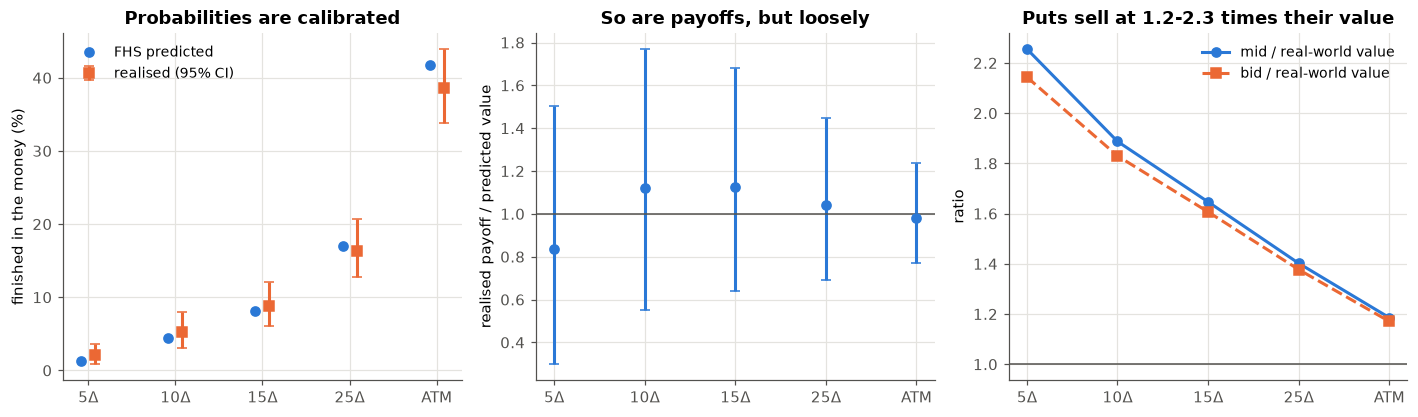

ok  no calibration test rejects after the Holm correction


In [6]:
x = np.arange(len(calibration))
labels = ["5Δ", "10Δ", "15Δ", "25Δ", "ATM"]
fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(13, 3.9))
real_lo = calibration.itm_pred + calibration.e_lo
real_hi = calibration.itm_pred + calibration.e_hi
a1.errorbar(x + 0.08, 100*calibration.itm_real, yerr=[100*(calibration.itm_real - real_lo), 100*(real_hi - calibration.itm_real)],
            fmt="s", color=ORANGE, capsize=3, label="realised (95% CI)")
a1.plot(x - 0.08, 100*calibration.itm_pred, "o", color=BLUE, label="FHS predicted")
a1.set(ylabel="finished in the money (%)", title="Probabilities are calibrated")
a1.legend(fontsize=9)
a2.errorbar(x, calibration.payoff_ratio, yerr=[calibration.payoff_ratio - calibration.ratio_lo,
                                               calibration.ratio_hi - calibration.payoff_ratio],
            fmt="o", color=BLUE, capsize=3)
a2.axhline(1, color=MUTED, lw=1)
a2.set(ylabel="realised payoff / predicted value", title="So are payoffs, but loosely")
a3.plot(x, compensation.kernel_mid_over_P, "o-", color=BLUE, label="mid / real-world value")
a3.plot(x, compensation.bid_bp/compensation.P_bp, "s--", color=ORANGE, label="bid / real-world value")
a3.axhline(1, color=MUTED, lw=1)
a3.set(ylabel="ratio", title="Puts sell at 1.2-2.3 times their value")
a3.legend(fontsize=9)
for a in (a1, a2, a3):
    a.set_xticks(x, labels)
fig.tight_layout()
plt.show()
check((calibration[["p_e_holm", "p_u_holm"]] > 0.05).all().all(), "no calibration test rejects after the Holm correction")

The left panel compares the predicted share of puts finishing in the money (blue) with the realised share and its 95%
interval (orange). Every prediction sits inside the interval, for example 8.1% predicted against 8.8% realised for the
15-delta put. The middle panel shows realised payoff divided by predicted value. All ratios are near 1, but the
intervals are wide, from about 0.3 to 1.5 for the 5-delta put. The right panel shows the market price divided by the
real-world value. The mid is 1.19 times the value at the money and rises steadily to 2.26 times at 5-delta, the same
pattern as the simple model in Section 1.

In [7]:
display(compensation.set_index("bucket")[["bid_bp", "P_bp", "payoff_bp", "C_bp", "C_share_of_bid", "C_pct_of_margin",
                                          "C_pct_of_stress", "C_bp_erp0", "C_bp_erp10", "pnl_unhedged_bp"]])
c15 = compensation.set_index("bucket").loc["15d"]
mde15 = calibration.set_index("bucket").loc["15d", "mde_u"]
print(f"15-delta put: compensation C = {c15.C_bp:.2f} bp per trade ({c15.C_share_of_bid:.0%} of the bid); "
      f"MDE of the payoff test = {mde15:.2f} bp")
check(mde15 > c15.C_bp, "the test can't resolve an error the size of the compensation, so the verdict is inconclusive")

,bid_bp,P_bp,payoff_bp,C_bp,C_share_of_bid,C_pct_of_margin,C_pct_of_stress,C_bp_erp0,C_bp_erp10,pnl_unhedged_bp
bucket,,,,,,,,,,
05d,5.524,2.577,2.154,2.947,0.533,0.187,0.490,2.822,3.062,3.369
10d,11.028,6.027,6.741,5.001,0.454,0.291,0.702,4.560,5.403,4.285
15d,16.927,10.535,11.853,6.392,0.378,0.356,0.827,5.578,7.131,5.070
25d,29.699,21.566,22.468,8.133,0.274,0.428,0.963,6.429,9.700,7.224
atm,67.833,57.946,56.785,9.887,0.146,0.479,1.060,5.665,13.824,11.032


15-delta put: compensation C = 6.39 bp per trade (38% of the bid); MDE of the payoff test = 7.78 bp
ok  the test can't resolve an error the size of the compensation, so the verdict is inconclusive


### What it means

For the 15-delta put the estimated compensation is $C$ = 6.4 bp per weekly trade, 38% of the bid. It moves between
5.6 and 7.1 bp when the assumed equity premium goes from 0% to 10%, so it is not an artefact of that assumption. No
calibration test rejects, and none of the entry states (skew, implied-vol gap, recent realised vol) predicts the errors
after the Holm correction.

But the MDE of the payoff test is 7.8 bp, larger than the 6.4 bp being measured. Five years of weekly SPY puts can't
distinguish a calibrated model from one that misses by the whole premium, so the verdict was recorded as
inconclusive, not as a pass. The premium is real in the sense that puts consistently sell well above every reasonable
estimate of their value, but its size can't be pinned down to the precision a trading rule would need.

The compensation per unit of risk is small. It is under 0.4% of the margin a broker requires and under 1% of the loss
in a one-day crash scenario (SPY −10%, implied vol +20 points), for every strike.

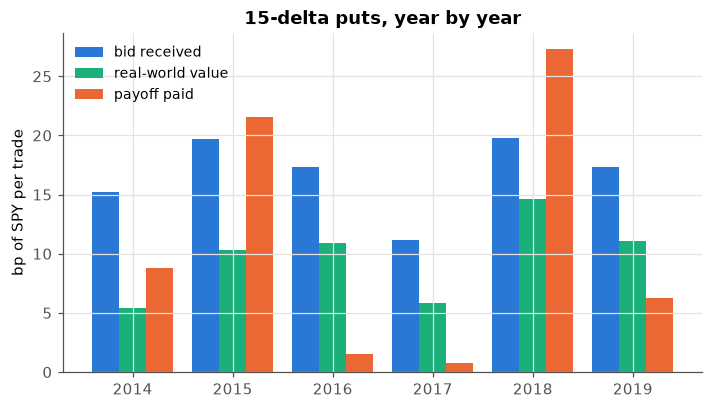

In [8]:
by_year = pd.DataFrame([
    (2014, 40, 15.2447, 5.3942, 8.8182, 0.076, 0.1),
    (2015, 56, 19.7152, 10.3071, 21.5615, 0.0813, 0.1607),
    (2016, 72, 17.3279, 10.8931, 1.532, 0.0818, 0.0278),
    (2017, 104, 11.1384, 5.814, 0.7953, 0.0712, 0.0288),
    (2018, 149, 19.7989, 14.5959, 27.2745, 0.0896, 0.1544),
    (2019, 147, 17.3119, 11.0709, 6.2287, 0.0805, 0.0612),
], columns=['year', 'n', 'bid_bp', 'P_fhs', 'payoff_bp', 'itm_pred_fhs', 'itm_real'])

fig, ax = plt.subplots(figsize=(7.5, 4))
x = np.arange(len(by_year))
ax.bar(x - 0.27, by_year.bid_bp, 0.27, color=BLUE, label="bid received")
ax.bar(x, by_year.P_fhs, 0.27, color=AQUA, label="real-world value")
ax.bar(x + 0.27, by_year.payoff_bp, 0.27, color=ORANGE, label="payoff paid")
ax.set_xticks(x, by_year.year)
ax.set(ylabel="bp of SPY per trade", title="15-delta puts, year by year")
ax.legend(fontsize=9)
plt.show()

The bars show, for the 15-delta put in each year, the average bid received, the average real-world value predicted by
FHS, and the average payoff the seller had to pay at expiry. In calm years like 2016 and 2017 the payoff is close to
zero and the seller keeps most of the bid. In 2015 and 2018 the payoff exceeds the bid, so the seller lost money over
the whole year. The predicted value stays between the two, as a calibrated model should. Over 2014–2019 the five
worst 15-delta weeks lost 342 to 384 bp each, and each of them wiped out about 60 weeks of average compensation.

## 5. Delta-hedging turns the put into a variance trade

Most professional sellers hedge the put's delta every day, which removes the exposure to the direction of SPY. What
is left can be understood exactly with a Taylor expansion of the option value. Work with Black-76 on the forward price
$F$ and implied vol $\sigma$, and ignore interest within a week. Over one day the short hedged put earns

$$\Pi = -\big(V(F+dF,\, t+dt,\, \sigma+d\sigma) - V(F,t,\sigma)\big) + \Delta\,dF$$

Expanding $V$ to second order in $dF$ and first order in $dt$ and $d\sigma$, the delta terms cancel and

$$\Pi \approx \underbrace{\Theta\,dt}_{\text{time decay}}\;\underbrace{-\;\tfrac12\Gamma\,dF^2}_{\text{realised moves}}\;\underbrace{-\;\mathcal V\,d\sigma}_{\text{vega}}\;+\;\text{residual}$$

where $\Theta = F\,n(d_1)\,\sigma/(2\sqrt T)$ is the rate of time decay, $\Gamma = n(d_1)/(F\sigma\sqrt T)$ and
$\mathcal V = F\,n(d_1)\sqrt T$. The residual collects everything of higher order, such as jumps, vanna and volga.

In Black-76 the time decay and the gamma are tied together, $\Theta = \tfrac12\sigma^2F^2\Gamma$. Substituting gives the
key identity of option trading

$$\Theta\,dt - \tfrac12\Gamma\,dF^2 = \tfrac12\,\Gamma F^2\Big(\sigma^2\,dt - \Big(\frac{dF}{F}\Big)^2\Big)$$

Each day the hedged seller earns the implied variance $\sigma^2dt$ and pays the realised variance $(dF/F)^2$, weighted
by the dollar gamma $\tfrac12\Gamma F^2$. That sum is the variance carry. If implied vol is above realised vol on
average, the hedged put makes money on average, whatever the direction of the market.

The cell below checks this in a simulated world. Options are priced at a constant 16% implied vol, while the real
vol of the underlying takes six values from 8% to 28%. For each value a 15-delta put with 5 days to expiry is sold and
delta-hedged daily until it settles, 20,000 times, and its P&L is split with the formulas above.

ok  the strike is the 15-delta put


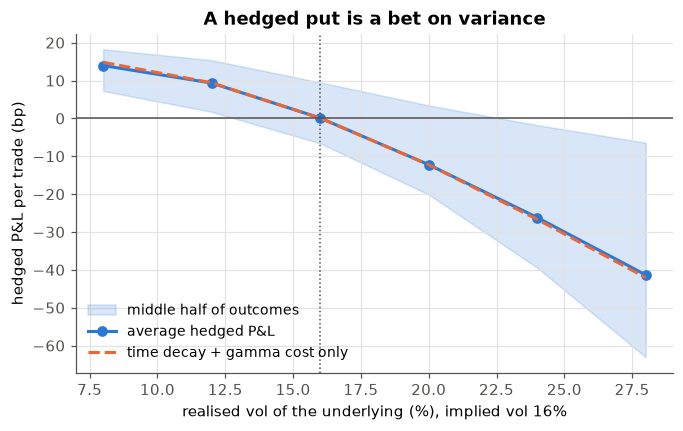

,mean,q25,q75,variance_carry
sigma_real,,,,
0.08,13.960,7.239,18.266,14.818
0.12,9.333,1.732,15.371,9.404
0.16,0.101,-6.586,9.502,0.065
0.20,-12.215,-20.120,3.426,-12.253
0.24,-26.179,-39.426,-1.782,-26.680
0.28,-41.335,-63.082,-6.411,-42.033


correlation of total P&L with variance carry (theta + gamma): 0.910
ok  variance carry explains the hedged P&L path by path
ok  the average P&L is zero when realised vol equals implied vol and falls as realised vol rises
ok  the components add up exactly


In [9]:
def greeks(F, K, T, sigma):
    sq = sigma*np.sqrt(T)
    d1 = np.log(F/K)/sq + sq/2
    n1 = norm.pdf(d1)
    return dict(value=K*norm.cdf(-(d1 - sq)) - F*norm.cdf(-d1), delta=-norm.cdf(-d1), gamma=n1/(F*sq),
                vega=F*n1*np.sqrt(T), theta=F*n1*sigma/(2*np.sqrt(T)))


def hedged_short_put(F0, K, days, sigma_impl, sigma_real, paths, seed=0):
    # daily steps of one calendar day and settlement at intrinsic value on the last day, returning per-path sums in bp
    rng = np.random.default_rng(seed)
    dt = 1/365
    F = np.full(paths, F0)
    parts = {k: np.zeros(paths) for k in ("total", "theta_carry", "gamma_cost", "vega", "residual")}
    realised = np.zeros(paths)
    for day in range(days):
        T = (days - day)*dt
        g = greeks(F, K, T, sigma_impl)
        F_new = F*np.exp(-0.5*sigma_real**2*dt + sigma_real*np.sqrt(dt)*rng.standard_normal(paths))
        V_new = np.maximum(K - F_new, 0) if day == days - 1 else greeks(F_new, K, T - dt, sigma_impl)["value"]
        dF = F_new - F
        total = -(V_new - g["value"]) + g["delta"]*dF
        theta, gamma = g["theta"]*dt, -0.5*g["gamma"]*dF**2
        for k, v in (("total", total), ("theta_carry", theta), ("gamma_cost", gamma), ("vega", 0*total),
                     ("residual", total - theta - gamma)):
            parts[k] += v*1e4/F0
        realised += np.log(F_new/F)**2
        F = F_new
    return pd.DataFrame(parts).assign(realised_vol=np.sqrt(realised/(days*dt)), sigma_real=sigma_real)


F0, days, sigma_impl = 100.0, 5, 0.16
K15 = F0*np.exp(sigma_impl*np.sqrt(days/365)*norm.ppf(0.15) + 0.5*sigma_impl**2*days/365)   # 15-delta strike
check(abs(greeks(F0, K15, days/365, sigma_impl)["delta"] + 0.15) < 1e-12, "the strike is the 15-delta put")
levels = np.array([0.08, 0.12, 0.16, 0.20, 0.24, 0.28])
n_paths = 20_000
sim = hedged_short_put(F0, K15, days, sigma_impl, np.repeat(levels, n_paths), len(levels)*n_paths, seed=12)
by_level = sim.groupby("sigma_real").agg(mean=("total", "mean"), q25=("total", lambda v: v.quantile(0.25)),
                                         q75=("total", lambda v: v.quantile(0.75)))
by_level["variance_carry"] = (sim.theta_carry + sim.gamma_cost).groupby(sim.sigma_real).mean()

fig, ax = plt.subplots()
ax.fill_between(100*levels, by_level.q25, by_level.q75, color=BLUE, alpha=0.18, label="middle half of outcomes")
ax.plot(100*levels, by_level["mean"], "o-", color=BLUE, label="average hedged P&L")
ax.plot(100*levels, by_level.variance_carry, "--", color=ORANGE, label="time decay + gamma cost only")
ax.axhline(0, color=MUTED, lw=1)
ax.axvline(100*sigma_impl, color=MUTED, lw=1, ls=":")
ax.set(xlabel="realised vol of the underlying (%), implied vol 16%", ylabel="hedged P&L per trade (bp)",
       title="A hedged put is a bet on variance")
ax.legend(fontsize=9)
plt.show()
display(by_level)
corr = np.corrcoef(sim.total, sim.theta_carry + sim.gamma_cost)[0, 1]
print(f"correlation of total P&L with variance carry (theta + gamma): {corr:.3f}")
check(corr > 0.9, "variance carry explains the hedged P&L path by path")
check(abs(by_level.loc[0.16, "mean"]) < 0.5 and by_level["mean"].is_monotonic_decreasing,
      "the average P&L is zero when realised vol equals implied vol and falls as realised vol rises")
check(np.allclose(sim.total, sim.theta_carry + sim.gamma_cost + sim.vega + sim.residual), "the components add up exactly")

The figure shows the hedged P&L of the short 15-delta put over its last 5 days, in bp, against the real vol of the
underlying, with options always priced at 16% implied vol. The blue line is the average over 20,000 paths and the band
holds the middle half of them. The average is zero where realised vol equals implied vol (dotted line), positive below
it and negative above it, and it falls faster as realised vol rises because the seller pays the square of the moves.
The dashed line, time decay plus the gamma cost alone, lies on top of the full P&L. A trade makes money when the
market moves less than the option price assumed, whichever direction it moves.

## 6. Where the real hedged put's P&L comes from

### The setup

The study took the 15-delta SPY put and sold it at the bid every trading day. Each position was delta-hedged at every
close with the quoted delta and closed at the ask 5 sessions later, or settled at intrinsic value if it expired. Each
day's P&L was split with Black-76 greeks computed at the previous close, using the forward from put-call parity and
the implied vol from that close's mid price. The split is exact by construction (the residual takes the rest), and
the study checked that the daily pieces add up to the P&L of the trading engine to $10^{-9}$. Development data is
2012–2019 (1,926 trades). The years 2020–2025 (1,490 trades) are shown as well. They had been seen before, so they
describe rather than test.

mean (bp)                        HAC t               
period         dev 2012-2019 seen 2020-2025 dev 2012-2019 seen 2020-2025
component                                                               
time decay            26.445         35.097        33.179         19.081
realised moves       -14.680        -26.059       -13.300         -8.695
vega                 -11.337        -11.335       -18.062        -14.286
residual               3.247          3.297         5.999          5.921
delta mismatch        -0.097          0.003        -0.932          0.022
costs                 -0.944         -0.311       -11.100         -8.598
net P&L                2.633          0.691         3.052          0.308

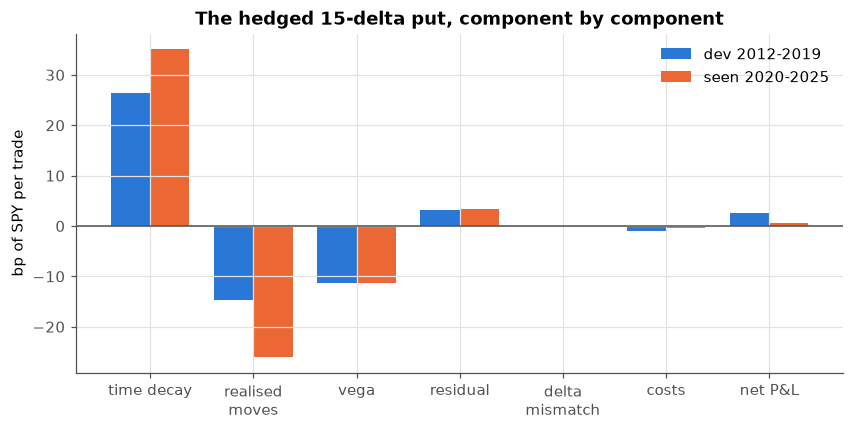

ok  the components add up to the net P&L


In [10]:
attribution = pd.DataFrame([
    ('dev 2012-2019', 'pnl_bidask', 2.633, 3.052, 21.363, -296.753),
    ('dev 2012-2019', 'total_mid', 3.577, 4.416, 20.381, -228.255),
    ('dev 2012-2019', 'theta_carry', 26.445, 33.179, 15.456, 7.327),
    ('dev 2012-2019', 'gamma_cost', -14.68, -13.3, 22.597, -269.23),
    ('dev 2012-2019', 'vega', -11.337, -18.062, 18.571, -366.712),
    ('dev 2012-2019', 'delta_mismatch', -0.097, -0.932, 3.802, -66.357),
    ('dev 2012-2019', 'residual', 3.247, 5.999, 15.477, -87.945),
    ('dev 2012-2019', 'variance_carry', 11.764, 17.088, 17.092, -220.674),
    ('dev 2012-2019', 'cost', -0.944, -11.1, 2.561, -68.498),
    ('dev 2012-2019', 'jump_loss', -1.778, -3.672, 13.231, -185.329),
    ('seen 2020-2025', 'pnl_bidask', 0.691, 0.308, 40.722, -633.348),
    ('seen 2020-2025', 'total_mid', 1.002, 0.452, 40.477, -622.949),
    ('seen 2020-2025', 'theta_carry', 35.097, 19.081, 27.86, 6.11),
    ('seen 2020-2025', 'gamma_cost', -26.059, -8.695, 45.493, -574.651),
    ('seen 2020-2025', 'vega', -11.335, -14.286, 20.409, -305.177),
    ('seen 2020-2025', 'delta_mismatch', 0.003, 0.022, 4.352, -51.768),
    ('seen 2020-2025', 'residual', 3.297, 5.921, 15.889, -124.233),
    ('seen 2020-2025', 'variance_carry', 9.038, 5.264, 32.638, -391.51),
    ('seen 2020-2025', 'cost', -0.311, -8.598, 0.826, -20.571),
    ('seen 2020-2025', 'jump_loss', -4.557, -3.127, 28.147, -400.523),
], columns=['period', 'component', 'mean_bp', 'hac_t', 'sd_bp', 'worst_bp'])

parts = ["theta_carry", "gamma_cost", "vega", "residual", "delta_mismatch", "cost", "pnl_bidask"]
names = ["time decay", "realised moves", "vega", "residual", "delta mismatch", "costs", "net P&L"]
table = attribution.pivot(index="component", columns="period", values="mean_bp").loc[parts]
t_stats = attribution.pivot(index="component", columns="period", values="hac_t").loc[parts]
display(pd.concat({"mean (bp)": table, "HAC t": t_stats}, axis=1).rename(index=dict(zip(parts, names))))

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(parts))
for k, (period, colour) in enumerate(zip(table.columns, (BLUE, ORANGE))):
    ax.bar(x + (k - 0.5)*0.38, table[period], 0.38, color=colour, label=period)
ax.axhline(0, color=MUTED, lw=1)
ax.set_xticks(x, [n.replace(" ", chr(10)) if n.startswith(("realised", "delta")) else n for n in names])
ax.set(ylabel="bp of SPY per trade", title="The hedged 15-delta put, component by component")
ax.legend()
plt.show()
dev = table["dev 2012-2019"]
check(abs(dev.drop("pnl_bidask").sum() - dev["pnl_bidask"]) < 0.01, "the components add up to the net P&L")

The bars show the average contribution of each part of the daily P&L per trade, in bp of SPY, for the development
years (blue) and 2020–2025 (orange). Time decay earns 26 bp a week in 2012–2019 and realised moves cost 15 bp. Vega
costs another 11 bp and the residual adds 3 bp. Delta mismatch, from hedging with the quoted delta instead of the
model delta, is close to zero, and costs take about 1 bp. The net is 2.6 bp a week in 2012–2019 (HAC t = 3.1) and
0.7 bp in 2020–2025, where realised moves cost 26 bp.

### Vega is not news

A loss of 11 bp a week from vega looks like the market repricing risk against the seller. It is not. The next table
splits the development days by the number of calendar days left to expiry and shows the average change in the put's
implied vol and the vega and residual terms on that day.

,days,dsig_pts,theta_carry,gamma_cost,vega,residual
days_left,,,,,,
1,560,0.00,6.37,-4.24,0.00,-1.76
2,1077,4.70,5.36,-3.41,-2.95,1.90
3,1054,2.23,5.10,-3.16,-2.25,0.40
4,1138,1.20,4.53,-2.89,-1.21,0.47
5-7,2803,2.33,7.16,-3.01,-5.20,2.06
8+,2998,0.06,3.67,-2.39,-0.10,-0.52


,days,dsig_pts,vega
group,,,
down day,4055,1.46,-2.68
settlement day,674,0.00,0.00
up day,4901,1.96,-2.24


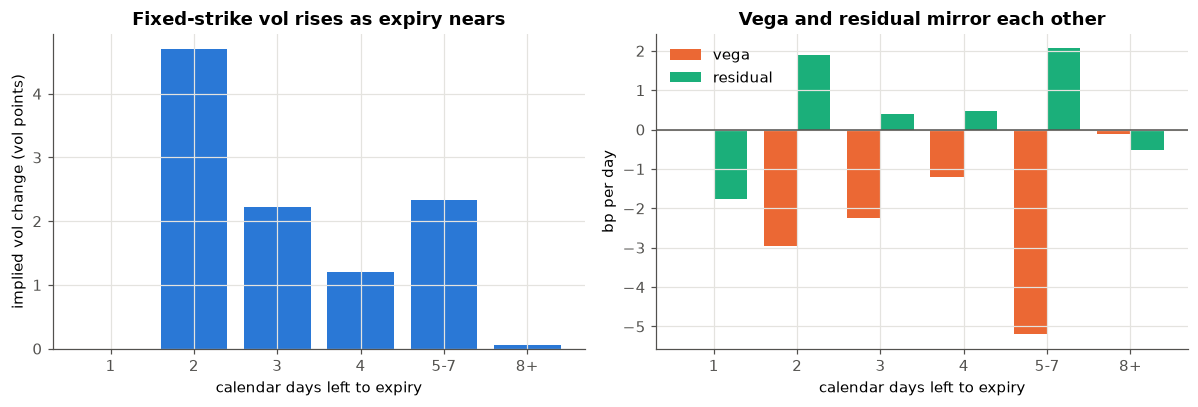

correlation of vega and residual across trades: -0.77
ok  vega and the residual move against each other


In [11]:
by_days_left = pd.DataFrame([
    ('1', 560, 0.0, 6.37, -4.24, 0.0, -1.76),
    ('2', 1077, 4.7, 5.36, -3.41, -2.95, 1.9),
    ('3', 1054, 2.23, 5.1, -3.16, -2.25, 0.4),
    ('4', 1138, 1.2, 4.53, -2.89, -1.21, 0.47),
    ('5-7', 2803, 2.33, 7.16, -3.01, -5.2, 2.06),
    ('8+', 2998, 0.06, 3.67, -2.39, -0.1, -0.52),
], columns=['days_left', 'days', 'dsig_pts', 'theta_carry', 'gamma_cost', 'vega', 'residual'])
up_down = pd.DataFrame([
    ('down day', 4055, 1.46, -2.68),
    ('settlement day', 674, 0.0, 0.0),
    ('up day', 4901, 1.96, -2.24),
], columns=['group', 'days', 'dsig_pts', 'vega'])

display(by_days_left.set_index("days_left"))
display(up_down.set_index("group"))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
x = np.arange(len(by_days_left))
a1.bar(x, by_days_left.dsig_pts, color=BLUE)
a1.set_xticks(x, by_days_left.days_left)
a1.set(xlabel="calendar days left to expiry", ylabel="implied vol change (vol points)",
       title="Fixed-strike vol rises as expiry nears")
a2.bar(x - 0.2, by_days_left.vega, 0.4, color=ORANGE, label="vega")
a2.bar(x + 0.2, by_days_left.residual, 0.4, color=AQUA, label="residual")
a2.axhline(0, color=MUTED, lw=1)
a2.set_xticks(x, by_days_left.days_left)
a2.set(xlabel="calendar days left to expiry", ylabel="bp per day", title="Vega and residual mirror each other")
a2.legend()
fig.tight_layout()
plt.show()
corr_vega_residual = -0.774   # across trades, 2012-2019
print(f"correlation of vega and residual across trades: {corr_vega_residual:.2f}")
check(corr_vega_residual < -0.7, "vega and the residual move against each other")

The left panel shows the average daily change in the 15-delta put's implied vol, by calendar days left to expiry. It
is positive almost everywhere and largest with 2 days left (+4.7 vol points), while on the settlement day the vol
term does not apply. The right panel shows the vega term (orange) and the residual (green) on the same days. Where
vega takes the most, the residual gives some of it back.

Two facts show that the vega term is mechanical rather than news. First, implied vol rises on up days (+2.0 points
on average) as well as down days (+1.5 points), which is not how a repricing of crash risk behaves. Second, it rises
most with 2 days to expiry. Weekly options price their last days at a higher variance rate than the days before, so
the same option's implied vol rises as it ages, even if nothing happens. The flat-vol convention computes time decay
at today's vol, so it books too much decay and then takes some of it back through vega. The residual absorbs the
higher-order part of the same effect, which is why the two correlate at −0.77.

The honest split therefore adds time decay, vega and residual into the decay the market actually allows along its
own vol surface. In 2012–2019 that is $26.4 - 11.3 + 3.2 \approx 18$ bp a week. Realised moves cost about 15 bp and
costs about 1 bp, which leaves the 2.6 bp net.

In [12]:
covid = pd.DataFrame([
    ('pnl_bidask', -2796.2),
    ('theta_carry', 5336.5),
    ('gamma_cost', -7167.0),
    ('vega', -1385.6),
    ('delta_mismatch', 35.8),
    ('residual', 480.2),
    ('variance_carry', -1830.4),
    ('cost', -96.1),
    ('jump_loss', -2179.4),
], columns=['component', 'sum_bp'])
exposure = pd.DataFrame([
    ('dev 2012-2019', 1926, 0.056, 0.286, 1.624, -6.843),
    ('seen 2020-2025', 1490, 0.111, 0.348, 2.681, -5.439),
], columns=['period', 'n', 'r2_market_only', 'r2_market_and_variance', 't_r', 't_r2'])

display(covid.set_index("component"))
display(exposure.set_index("period"))
c = covid.set_index("component").sum_bp
check(c["gamma_cost"] < 3*c["vega"], "in the COVID crash realised moves cost over three times as much as vega")

,sum_bp
component,
pnl_bidask,-2796.2
theta_carry,5336.5
gamma_cost,-7167.0
vega,-1385.6
delta_mismatch,35.8
residual,480.2
variance_carry,-1830.4
cost,-96.1
jump_loss,-2179.4


,n,r2_market_only,r2_market_and_variance,t_r,t_r2
period,,,,,
dev 2012-2019,1926,0.056,0.286,1.624,-6.843
seen 2020-2025,1490,0.111,0.348,2.681,-5.439


ok  in the COVID crash realised moves cost over three times as much as vega


### Crashes and exposure

The first table sums each component over the 53 trades opened between 14 February and 30 April 2020. They lost 2,796
bp in total. Realised moves cost 7,167 bp against 5,337 bp of time decay, while the vega term cost only 1,386 bp. The
crash hurt through the size of the daily moves, not through a jump in implied vol. With one trade opened every day, a
loss of this size is more than four years of the 2012–2019 average net P&L.

The second table regresses each trade's P&L on the week's SPY log return $r$ and its square $r^2$. The return alone
explains 6–11% of the variance, and adding $r^2$ raises it to 29–35%, with a strongly negative coefficient on $r^2$
(t = −6.8 and −5.4). The hedged put is short variance, and most of its week-to-week P&L is noise around that.

## 7. Conclusions

- SPY puts sell well above their real-world value, at 1.2 times at the money and 2.3 times at 5-delta. That pattern is
  what a premium for crash insurance looks like.
- For the 15-delta put the compensation is about 6.4 bp a week, 38% of the bid. With five years of data its size
  can't be pinned down more precisely than the premium itself, so it supports no trading rule.
- Delta-hedged, the put is variance carry. It earns about 18 bp of decay along the market's vol surface, pays about 15
  bp for realised moves and 1 bp in costs, and nets 2.6 bp a week in 2012–2019.
- The vega term is a mechanical roll along the term structure of weekly options, not news. No component other than
  variance carry and costs is large and separate, so there is no hidden second source of return to target.
- The premium is thin compared with its risks. One bad week costs about a year of it, and short volatility loses
  money in crashes, so it is not a hedge.

### Limitations

- The real-world model assumes the 5-day standardised returns of the past are a good guide to the next week. A crash
  bigger than any in the pool gets a probability of zero under FHS.
- Only 568 origins qualify for the valuation study, and their 5-day windows overlap, so its precision is limited.
- End-of-day quotes are a snapshot, fills at the bid and ask are an assumption, and early exercise of these American
  options is ignored.
- The equity risk premium in the real-world drift is assumed at 5% a year (0% and 10% are reported).

### References

- Barone-Adesi, G., Giannopoulos, K. and Vosper, L. (1999). VaR without correlations for portfolios of derivative
  securities. Journal of Futures Markets.
- Bondarenko, O. (2014). Why are put options so expensive? Quarterly Journal of Finance.
- Carr, P. and Wu, L. (2009). Variance risk premiums. Review of Financial Studies.
- Fournier, M., Jacobs, K. and Orlowski, P. (2024). Modeling conditional factor risk premia implied by index option
  returns. Journal of Finance.
- Jones, M. C. and Faddy, M. J. (2003). A skew extension of the t-distribution, with applications. Journal of the Royal
  Statistical Society B.
- Künsch, H. R. (1989). The jackknife and the bootstrap for general stationary observations. Annals of Statistics.
- Holm, S. (1979). A simple sequentially rejective multiple test procedure. Scandinavian Journal of Statistics.
- Newey, W. and West, K. (1987). A simple, positive semi-definite, heteroskedasticity and autocorrelation consistent
  covariance matrix. Econometrica.